# Bài thực hành B1
## Khám phá bộ dữ liệu IDS phát hiện bất thường trong mạng

Mục tiêu:

- Làm quen với bộ dữ liệu CICMAL2017
- Thực hiện làm sạch dữ liệu
- Trực quan hóa dữ liệu bằng biểu đồ
- Tìm hiểu các đặc trưng liên quan tới tấn công mạng
- Phát hiện các nhóm đặc trưng có xu hướng thay đổi giống nhau
ac
Sau khi hoàn thành bài thực hành, học viên có thể hiểu cách dữ liệu mạng được sử dụng trong các hệ thống phát hiện tấn công sử dụng trí tuệ nhân tạo.

In [39]:
# ==========================================================
# IMPORT THƯ VIỆN
# ==========================================================

# Xử lý dữ liệu dạng bảng
import pandas as pd

# Tính toán số học
import numpy as np

# Vẽ biểu đồ
import matplotlib.pyplot as plt
import seaborn as sns

# Tiền xử lý dữ liệu
from sklearn.preprocessing import LabelEncoder

# Quản lý đường dẫn file
from pathlib import Path

plt.style.use("default")
sns.set_theme(style="whitegrid")

## Bước 1. Đọc dữ liệu

Bộ dữ liệu CICMAL2017 chứa các phiên giao tiếp mạng (network flows)
được gắn nhãn bình thường hoặc mã độc.

In [40]:
# ==========================
# Xác định đường dẫn tới file dữ liệu
# ==========================

# Lấy thư mục làm việc hiện tại (thư mục chứa notebook/script đang chạy)
root_folder = Path.cwd()

# Tạo đường dẫn tới file CSV:
# root_folder/
# └── Dataset/
#     └── category_CICMAL2017_dataset.csv
CSV_PATH = root_folder.parent / "Dataset" / "category_CICMAL2017_dataset.csv"

# ==========================
# Đọc dữ liệu từ file CSV
# ==========================

# low_memory=False:
# Đọc toàn bộ dữ liệu trước khi suy luận kiểu dữ liệu của từng cột,
# giúp tránh cảnh báo "DtypeWarning" khi các cột có nhiều kiểu dữ liệu khác nhau.
df_raw = pd.read_csv(CSV_PATH, low_memory=False)

# ==========================
# Khám phá dữ liệu ban đầu
# ==========================

# Hiển thị số lượng hàng và cột của tập dữ liệu
print("Kích thước dữ liệu:", df_raw.shape)

# Xem 5 dòng đầu tiên để kiểm tra cấu trúc dữ liệu
df_raw.head()

Kích thước dữ liệu: (22192, 86)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Binary Label,Cat_Label
0,172.217.6.238-10.42.0.42-443-53638-17,10.42.0.42,0.051315,172.217.6.238,0.000334,0.000038,07/07/2017 03:46:43,0.126772,0.000258,0.000006,...,0.002759,0.000000,0.002759,0.002759,0.124434,0.000000,0.124434,0.124434,0,Benign
1,203.205.158.61-10.42.0.151-80-37004-6,10.42.0.151,0.035401,203.205.158.61,0.000060,0.000014,30/06/2017 03:37:16,0.207822,0.000074,0.000002,...,0.001902,0.004829,0.003784,0.000019,0.102749,0.037526,0.119640,0.085858,1,SMSMALWARE_FAKEINST
2,10.42.0.42-121.14.255.98-42255-80-6,10.42.0.42,0.040425,121.14.255.98,0.000060,0.000014,06/07/2017 11:35:58,0.086790,0.000368,0.000010,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,Benign
3,220.243.219.55-10.42.0.151-80-42663-6,10.42.0.151,0.040815,220.243.219.55,0.000060,0.000014,20/06/2017 05:15:37,0.250329,0.000147,0.000004,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,Benign
4,151.101.117.140-10.42.0.211-443-56183-6,10.42.0.211,0.053750,151.101.117.140,0.000334,0.000014,05/08/2017 12:10:05,0.000371,0.000000,0.000002,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,Benign


## Bước 2. Quan sát dữ liệu

Mỗi dòng biểu diễn một luồng lưu lượng mạng.

Các cột cuối:

- Binary Label
- Cat_Label

chính là nhãn phân loại.

In [41]:
# ==========================
# Kiểm tra thông tin tổng quan của DataFrame
# ==========================

# info() hiển thị:
# - Số lượng dòng (entries) của tập dữ liệu
# - Danh sách các cột và thứ tự của chúng
# - Số lượng giá trị không bị thiếu (Non-Null Count) của từng cột
# - Kiểu dữ liệu của từng cột (int, float, object,...)
# - Dung lượng bộ nhớ mà DataFrame đang sử dụng

print(df_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22192 entries, 0 to 22191
Data columns (total 86 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Flow ID                      22191 non-null  object 
 1   Source IP                    22192 non-null  object 
 2   Source Port                  22192 non-null  float64
 3   Destination IP               22192 non-null  object 
 4   Destination Port             22192 non-null  float64
 5   Protocol                     22192 non-null  float64
 6   Timestamp                    22192 non-null  object 
 7   Flow Duration                22192 non-null  float64
 8   Total Fwd Packets            22192 non-null  float64
 9   Total Backward Packets       22192 non-null  float64
 10  Total Length of Fwd Packets  22192 non-null  float64
 11  Total Length of Bwd Packets  22192 non-null  float64
 12  Fwd Packet Length Max        22192 non-null  float64
 13  Fwd Packet Lengt

## Bước 3. Làm sạch dữ liệu

Dữ liệu thực tế thường chứa:

- Giá trị bị thiếu
- Giá trị bất thường
- Thông tin không cần thiết

In [42]:
# ==========================
# Tách đặc trưng (X) và nhãn (y)
# ==========================

# Danh sách các cột không sử dụng để huấn luyện mô hình
DROP_COLS = [
    "Flow ID",  # Mã định danh của luồng mạng
    "Src IP",  # Địa chỉ IP nguồn
    "Dst IP",  # Địa chỉ IP đích
    "Src Port",  # Cổng nguồn
    "Dst Port",  # Cổng đích
    "Protocol",  # Giao thức mạng (TCP, UDP,...)
    "Timestamp",  # Thời gian ghi nhận luồng mạng
    "Binary Label",  # Nhãn phân loại nhị phân (Normal/Attack)
    "Cat_Label",  # Nhãn đa lớp cần dự đoán
]

# Tạo tập đặc trưng X bằng cách loại bỏ các cột không cần thiết
# errors="ignore" giúp chương trình không báo lỗi nếu một cột
# trong DROP_COLS không tồn tại trong DataFrame
X = df_raw.drop(columns=DROP_COLS, errors="ignore")

# Tạo vector nhãn y
# Cat_Label là nhãn đa lớp biểu diễn loại tấn công tương ứng
y = df_raw["Cat_Label"]

In [43]:
# ==========================
# Kiểm tra giá trị thiếu (Missing Values)
# ==========================

# isnull():
# Kiểm tra từng ô trong DataFrame có bị thiếu (NaN) hay không.
# Kết quả trả về là DataFrame gồm các giá trị True/False:
# True  -> giá trị bị thiếu
# False -> giá trị hợp lệ

# sum() lần thứ nhất:
# Đếm số lượng giá trị thiếu của từng cột.

# sum() lần thứ hai:
# Cộng tổng số giá trị thiếu của tất cả các cột,
# thu được tổng số ô bị thiếu trong toàn bộ tập dữ liệu.
missing = X.isnull().sum().sum()

# Hiển thị tổng số giá trị thiếu
print("Số giá trị thiếu:", missing)

Số giá trị thiếu: 0


In [44]:
# ==========================
# Tiền xử lý dữ liệu số
# ==========================

# Chỉ giữ lại các cột có kiểu dữ liệu là số (int, float)
# Các cột dạng chuỗi (object) sẽ bị loại bỏ.
# Điều này giúp đảm bảo dữ liệu phù hợp với các mô hình Machine Learning.
X = X.select_dtypes(include=np.number)

# Thay thế các giá trị vô cùng:
#  np.inf  : dương vô cùng
# -np.inf  : âm vô cùng
# bằng giá trị NaN (giá trị thiếu).
# Các giá trị này thường xuất hiện khi chia cho 0
# hoặc do lỗi trong quá trình tính toán đặc trưng.
X = X.replace([np.inf, -np.inf], np.nan)

# Điền các giá trị thiếu (NaN) bằng giá trị trung vị (median)
# của từng cột.
#
# Median được ưu tiên hơn mean vì:
# - Ít bị ảnh hưởng bởi các giá trị ngoại lai (outliers).
# - Phù hợp với dữ liệu mạng thường có phân bố lệch.
X = X.fillna(X.median())

## Bước 4. Đặc trưng nào liên quan nhiều nhất tới tấn công?

In [45]:
# ==========================================================
# TÌM MỨC ĐỘ LIÊN QUAN GIỮA TỪNG ĐẶC TRƯNG VÀ NHÃN PHÂN LOẠI
# ==========================================================

# Máy tính chỉ làm việc với số.
# Vì vậy cần chuyển các nhãn dạng chữ
# (Benign, Ransomware, Spyware, ...)
# thành các giá trị số.
le = LabelEncoder()

# Thực hiện mã hóa nhãn
label_enc = le.fit_transform(y)

# Tạo một bảng dữ liệu mới từ tập đặc trưng
corr = pd.DataFrame(X)

# Thêm cột nhãn đã được chuyển thành số
corr["label"] = label_enc

# ----------------------------------------------------------
# Tính hệ số tương quan Pearson
# ----------------------------------------------------------
# Hệ số tương quan cho biết mức độ liên hệ giữa hai biến.
#
# Giá trị gần 1  : liên hệ mạnh theo chiều tăng
# Giá trị gần -1 : liên hệ mạnh theo chiều giảm
# Giá trị gần 0  : ít hoặc không có liên hệ rõ ràng
#
# Ở đây ta quan tâm tới mức độ liên hệ giữa
# từng đặc trưng mạng và nhãn phân loại.
corr_with_label = (
    corr.corr()["label"]
    .drop("label")      # bỏ chính cột nhãn
)

# ----------------------------------------------------------
# Sắp xếp theo độ mạnh của tương quan
# ----------------------------------------------------------
# Lấy giá trị tuyệt đối để chỉ quan tâm
# tương quan mạnh hay yếu,
# không phân biệt tăng hay giảm.
corr_abs = (
    corr_with_label.abs()
    .sort_values(ascending=False)
)

# Hiển thị 10 đặc trưng có liên hệ mạnh nhất với nhãn
corr_abs.head(10)

Idle Max         0.296617
Flow Duration    0.296132
Fwd IAT Max      0.295443
Fwd IAT Total    0.286711
Flow IAT Max     0.273177
Idle Mean        0.248670
Fwd IAT Std      0.245677
Bwd IAT Total    0.244265
Idle Std         0.241336
Bwd IAT Max      0.228440
Name: label, dtype: float64

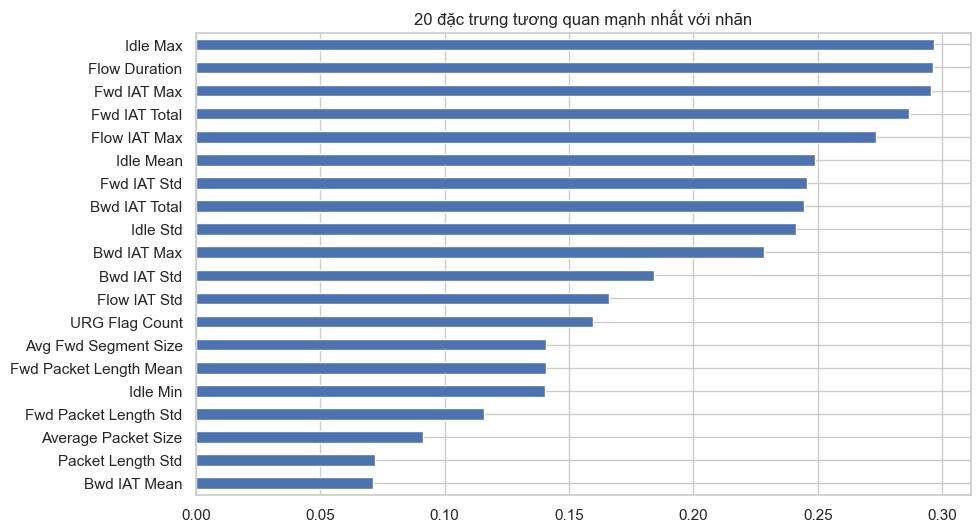

In [46]:
# ==========================
# Trực quan hóa 20 đặc trưng có tương quan mạnh nhất với nhãn
# ==========================

# Lấy 20 đặc trưng có độ tương quan tuyệt đối lớn nhất
# corr_abs là Series đã được sắp xếp giảm dần theo |correlation|
top20 = corr_abs.head(20)

# Tạo khung hình với kích thước 10x6 inch
plt.figure(figsize=(10, 6))

# Sắp xếp tăng dần để khi vẽ biểu đồ ngang,
# đặc trưng có tương quan mạnh nhất nằm ở phía trên
top20.sort_values().plot(kind="barh")  # barh = horizontal bar chart (biểu đồ cột ngang)

# Đặt tiêu đề cho biểu đồ
plt.title("20 đặc trưng tương quan mạnh nhất với nhãn")

# Hiển thị biểu đồ
plt.show()

Những đặc trưng nào có liên quan mạnh nhất tới tấn công?

Các đặc trưng này mô tả điều gì?

## Bước 5. Có đặc trưng nào gần như giống nhau không?

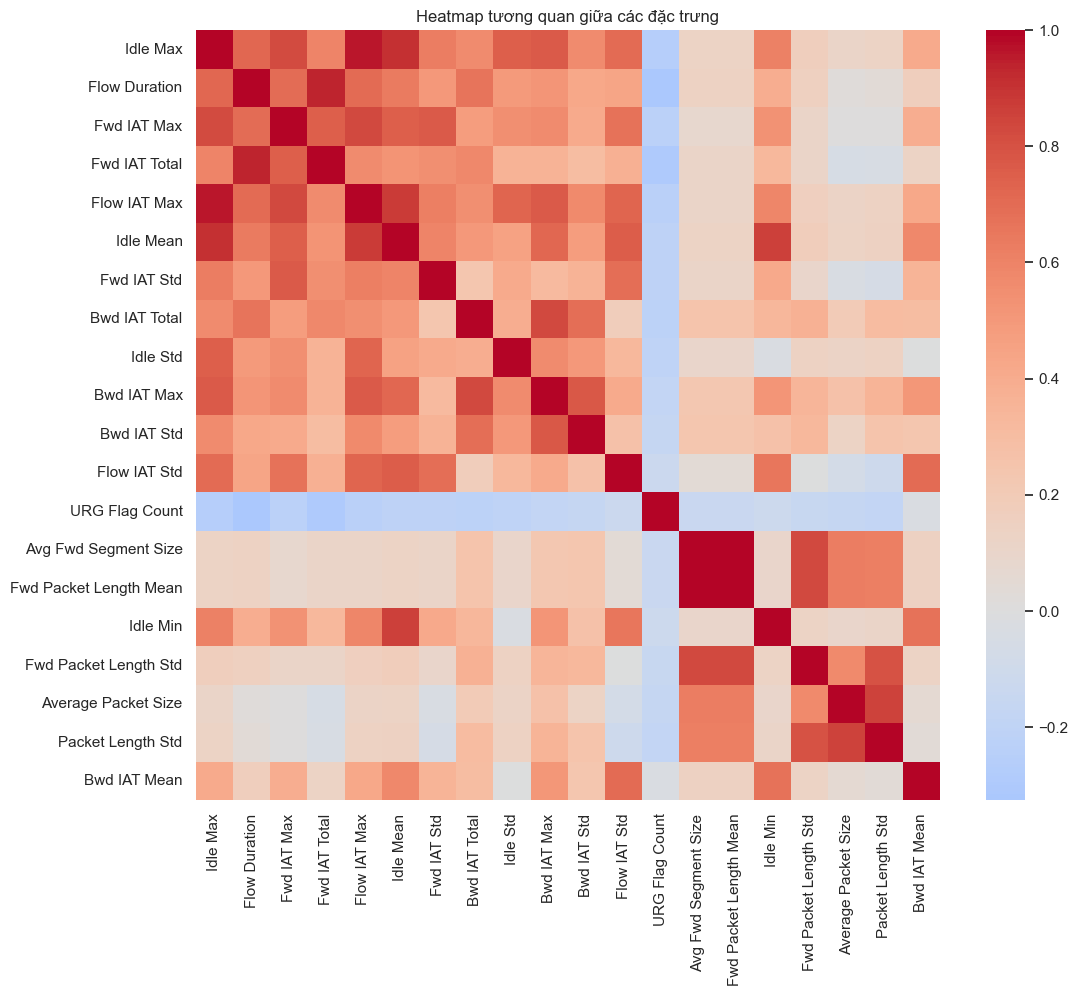

In [47]:
# ==========================================================
# HEATMAP TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG QUAN TRỌNG
# ==========================================================

# Lấy 20 đặc trưng có mức liên hệ mạnh nhất với nhãn phân loại
# (được xác định ở bước trước)
top_feats = (
    corr_abs.head(20)
    .index
)

# ----------------------------------------------------------
# Tính ma trận tương quan
# ----------------------------------------------------------
# Ma trận tương quan cho biết mức độ liên hệ
# giữa từng cặp đặc trưng.
#
# Ví dụ:
# - Nếu hai đặc trưng luôn thay đổi cùng nhau,
#   hệ số tương quan sẽ gần 1.
#
# - Nếu một đặc trưng tăng khi đặc trưng kia giảm,
#   hệ số tương quan sẽ gần -1.
#
# - Nếu không có mối liên hệ rõ ràng,
#   hệ số tương quan sẽ gần 0.
corr_matrix = (
    X[top_feats]
    .corr()
)

# ----------------------------------------------------------
# Trực quan hóa bằng Heatmap
# ----------------------------------------------------------
# Heatmap sử dụng màu sắc để thể hiện mức độ tương quan:
#
# Đỏ đậm  : tương quan dương mạnh
# Xanh đậm: tương quan âm mạnh
# Màu nhạt: tương quan yếu
#
# Mục tiêu:
# - Tìm các đặc trưng có xu hướng thay đổi giống nhau
# - Phát hiện các nhóm đặc trưng có thể chứa thông tin trùng lặp
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0
)

plt.title(
    "Heatmap tương quan giữa các đặc trưng"
)

plt.show()

Có cặp đặc trưng nào tương quan rất cao không?

Nếu hai đặc trưng gần như giống nhau,
có cần giữ cả hai không?

## Bước 6. Khi bị tấn công, điều gì thay đổi nhiều nhất?

In [48]:
# ==========================================================
# XÁC ĐỊNH CÁC ĐẶC TRƯNG THAY ĐỔI NHIỀU NHẤT KHI BỊ TẤN CÔNG
# ==========================================================

# Tách dữ liệu thành hai nhóm:
#
# 1. Benign  : lưu lượng mạng bình thường
# 2. Attack  : lưu lượng mạng có chứa mã độc hoặc tấn công
#
# Mục tiêu là so sánh sự khác biệt giữa hai nhóm này.

benign = X[
    y == "Benign"
]

attack = X[
    y != "Benign"
]

# ----------------------------------------------------------
# Tính giá trị trung bình của từng đặc trưng
# ----------------------------------------------------------
#
# Ví dụ:
# Flow Duration
# Benign  : 100
# Attack  : 250
#
# Khi đó có thể thấy đặc trưng này thay đổi đáng kể
# khi xảy ra tấn công.
#
# Công thức dưới đây đo mức độ thay đổi tương đối:
#
# |Mean_Attack - Mean_Benign|
# ---------------------------
#        Mean_Benign
#
# Giá trị càng lớn:
# => đặc trưng càng thay đổi mạnh
# => càng có khả năng liên quan tới hành vi tấn công

ratio = (
    (
        attack.mean()
        -
        benign.mean()
    ).abs()
    /
    (
        benign.mean().abs()
        + 1e-9
    )
)

# ----------------------------------------------------------
# Sắp xếp theo mức độ thay đổi giảm dần
# ----------------------------------------------------------
#
# Đặc trưng đứng đầu danh sách là những đặc trưng
# thay đổi mạnh nhất giữa lưu lượng bình thường
# và lưu lượng tấn công.
ratio = ratio.sort_values(
    ascending=False
)

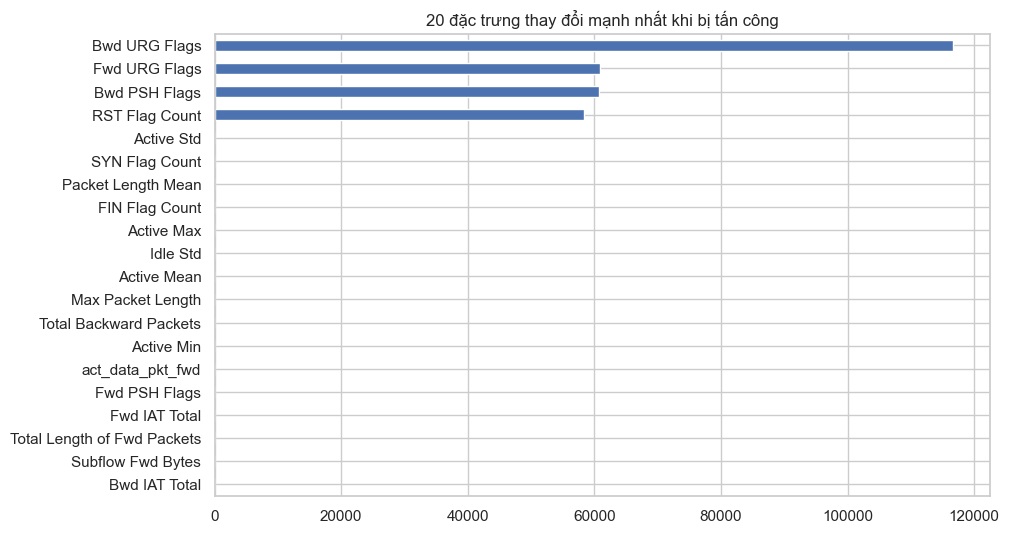

In [49]:
ratio.head(20).sort_values().plot(
    kind="barh",
    figsize=(10,6)
)

plt.title(
    "20 đặc trưng thay đổi mạnh nhất khi bị tấn công"
)

plt.show()